# Step 10: Error analysis like a sensor-validation engineer

A single MAE number is not a validation. This notebook asks the questions a wearable-company validation team asks:

1. How well does the estimate **agree** with ECG overall (bias, limits of agreement)?
2. **When** does it fail: which activities, how much motion, which heart rates?
3. **How** does it fail: harmonics, locking onto motion, or something else?
4. **For whom** does it fail, and can this dataset even answer fairness questions (e.g., skin tone)?
5. Are the improvements **statistically** real across people?

All predictions are leave-one-subject-out (every estimate is for a person the model never trained on).

## 1. Load every method's predictions

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from ppghr.data import ACTIVITY_NAMES, PROCESSED_DIR, PROJECT_DIR, SUBJECTS, load_processed
from ppghr.baseline import estimate_hr_fft
from ppghr.features import peak_features
from ppghr.windows import load_all_windows
from ppghr.validation import agreement, bland_altman, classify_big_errors

data = load_all_windows()
truth, subjects = data["hr"].astype(float), data["subject"]
activity = np.array([ACTIVITY_NAMES[a] for a in data["activity"]])

methods = {
    "FFT baseline": estimate_hr_fft(data["ppg"]),
    "Gradient boosting": np.load(PROCESSED_DIR.parent / "step8_predictions.npz")["predictions"],
    "CNN (1 network)": np.load(PROCESSED_DIR.parent / "step9_predictions.npz")["cnn"],
    "CNN ensemble (3)": np.load(PROCESSED_DIR.parent / "step9_ensemble_predictions.npy"),
}
final = methods["CNN ensemble (3)"]
motion = np.linalg.norm(data["acc"], axis=2).std(axis=1)      # how much the wrist moved in each window
motion_peaks = peak_features(data)[:, 10:13]                      # bpm of the 3 tallest motion peaks
print(f"{len(truth)} windows, {len(np.unique(subjects))} people")

64697 windows, 15 people


## 2. Agreement with ECG

**Bias** = average of (estimate - ECG): does the method read high or low on average?  
**Limits of agreement** = bias +/- 1.96 standard deviations: about 95% of windows fall in this range.  
**Within 5 bpm or 10%** borrows a yardstick used for medical heart-rate meters (the larger of +/-5 bpm or +/-10%). It's a reference point, not a certification.

In [2]:
table = pd.DataFrame({name: agreement(p, truth) for name, p in methods.items()}).T
table.round(2)

,MAE (bpm),RMSE (bpm),MAPE (%),bias (bpm),lower limit of agreement (bpm),upper limit of agreement (bpm),95th percentile error (bpm),Pearson r,within 5 bpm (%),within 5 bpm or 10% (%)
FFT baseline,17.80,30.10,17.97,-15.01,-66.14,36.11,70.16,0.40,53.61,57.64
Gradient boosting,7.48,12.95,8.10,-0.79,-26.11,24.54,29.66,0.82,61.50,71.45
CNN (1 network),5.96,12.50,6.70,-0.30,-24.79,24.19,27.76,0.85,73.46,82.24
CNN ensemble (3),5.59,11.36,6.29,-0.33,-22.58,21.93,25.38,0.87,73.60,82.52


## 3. Bland-Altman plots (the standard figure in device-validation papers)

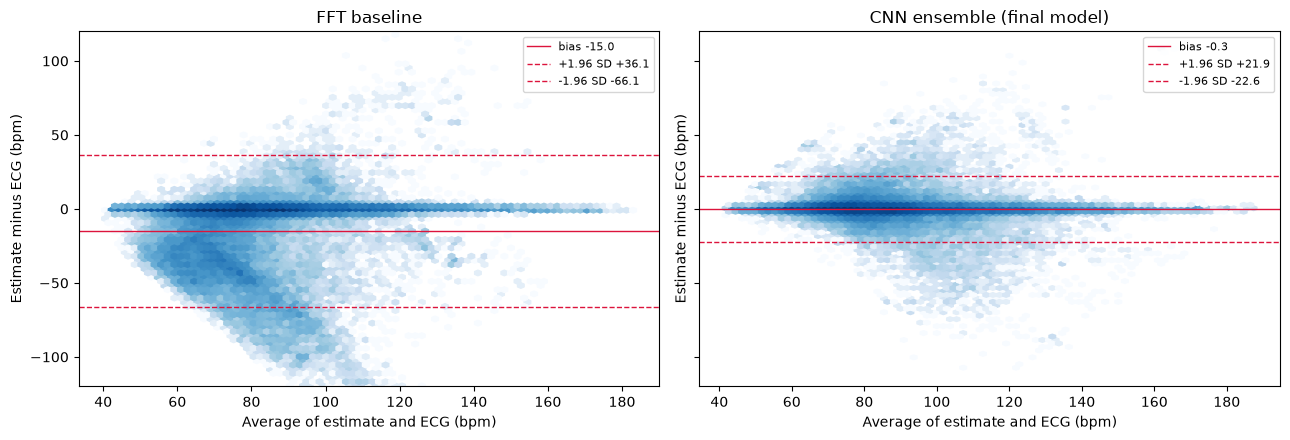

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
bland_altman(axes[0], methods["FFT baseline"], truth, "FFT baseline")
bland_altman(axes[1], final, truth, "CNN ensemble (final model)")
axes[0].set_ylim(-120, 120)
plt.tight_layout()
plt.show()

## 4. When does it fail? Error vs. activity, motion and heart rate

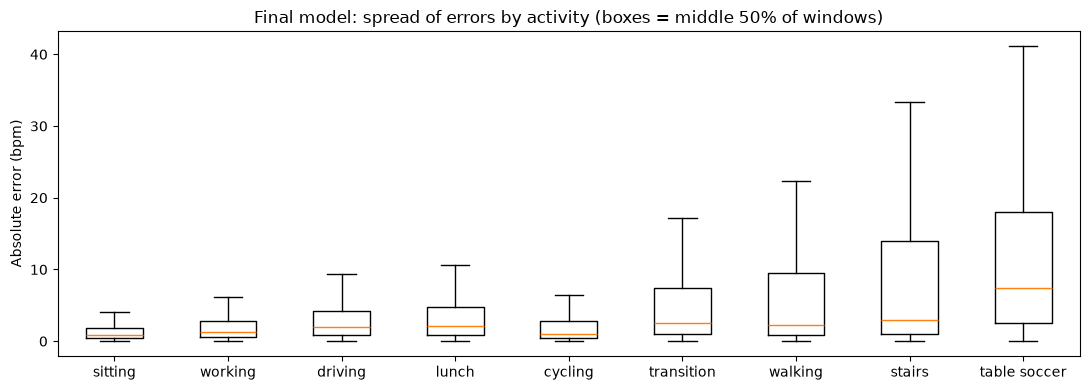

,FFT baseline,Gradient boosting,CNN (1 network),CNN ensemble (3)
activity,,,,
sitting,2.7,3.5,3.0,2.9
working,8.0,3.8,3.1,2.9
driving,12.2,5.3,4.1,3.8
lunch,13.2,5.2,4.6,4.3
cycling,27.9,9.8,5.7,5.5
transition,22.2,9.1,7.1,6.7
walking,27.8,10.2,8.5,7.9
stairs,37.8,17.0,11.6,10.8
table soccer,30.2,14.0,14.5,13.4


In [4]:
errors = pd.DataFrame({name: np.abs(p - truth) for name, p in methods.items()})
errors["activity"] = activity
by_activity = errors.groupby("activity").mean().round(1).sort_values("CNN ensemble (3)")

order = by_activity.index
plt.figure(figsize=(11, 4))
plt.boxplot([np.abs(final - truth)[activity == a] for a in order], tick_labels=order, showfliers=False)
plt.ylabel("Absolute error (bpm)")
plt.title("Final model: spread of errors by activity (boxes = middle 50% of windows)")
plt.tight_layout()
plt.show()
by_activity

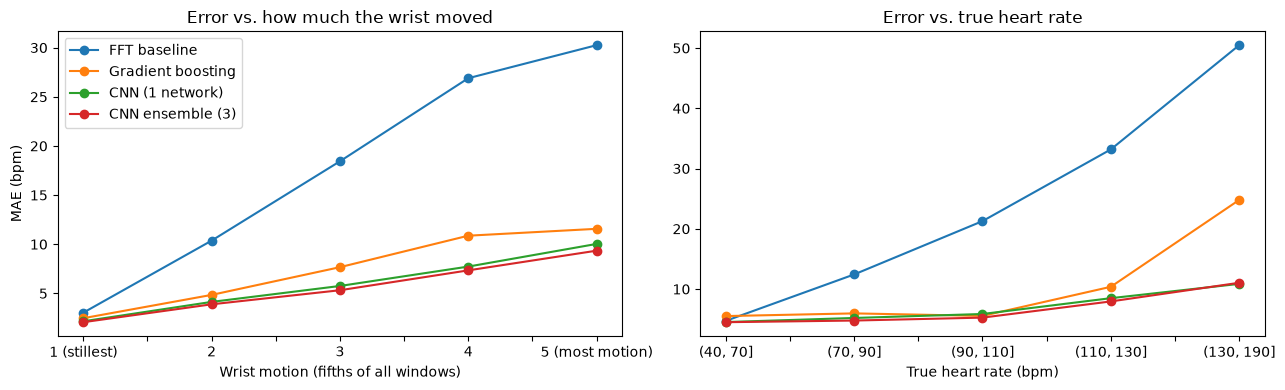

In [5]:
motion_bins = pd.qcut(motion, 5, labels=["1 (stillest)", "2", "3", "4", "5 (most motion)"])
hr_bins = pd.cut(truth, [40, 70, 90, 110, 130, 190])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
errors.groupby(motion_bins, observed=True)[list(methods)].mean().plot(ax=axes[0], marker="o")
axes[0].set_xlabel("Wrist motion (fifths of all windows)")
axes[0].set_ylabel("MAE (bpm)")
axes[0].set_title("Error vs. how much the wrist moved")
errors.groupby(hr_bins, observed=True)[list(methods)].mean().plot(ax=axes[1], marker="o", legend=False)
axes[1].set_xlabel("True heart rate (bpm)")
axes[1].set_title("Error vs. true heart rate")
plt.tight_layout()
plt.show()

## 5. How does it fail? Anatomy of big errors (> 20 bpm)

In [6]:
anatomy = pd.DataFrame({
    name: pd.Series(classify_big_errors(p, truth, motion_peaks)).value_counts(normalize=True) * 100
    for name, p in methods.items()
}).fillna(0).round(1)
anatomy

,FFT baseline,Gradient boosting,CNN (1 network),CNN ensemble (3)
half or double the true HR,8.3,0.1,0.7,0.3
locked onto a motion rhythm,13.7,3.7,1.8,1.8
other big error,10.7,6.9,5.0,4.9
small error (<= 20 bpm),67.3,89.3,92.5,92.9


## 6. For whom does it fail? People, their characteristics, and what this dataset can't tell us

In [7]:
people = pd.DataFrame([{k: load_processed(s)[k].item() for k in
                        ["age", "gender", "height_cm", "weight_kg", "skin_type", "sport"]}
                       for s in SUBJECTS], index=SUBJECTS)
for name, p in methods.items():
    people[f"MAE: {name}"] = [np.abs(p - truth)[subjects == int(s[1:])].mean() for s in SUBJECTS]
print("Skin types in the dataset (Fitzpatrick scale 1 = lightest ... 6 = darkest):")
print(people["skin_type"].value_counts().sort_index().to_string())
people.round(1)

Skin types in the dataset (Fitzpatrick scale 1 = lightest ... 6 = darkest):
skin_type
2     1
3    11
4     3


,age,gender,height_cm,weight_kg,skin_type,sport,MAE: FFT baseline,MAE: Gradient boosting,MAE: CNN (1 network),MAE: CNN ensemble (3)
S1,34,m,182.0,78.0,3,6,11.6,6.9,6.2,5.9
S2,28,m,189.0,80.0,3,5,14.1,5.3,5.3,4.9
S3,25,m,170.0,60.0,3,5,17.0,4.1,3.4,3.2
S4,25,m,168.0,57.0,4,5,20.7,6.5,7.7,7.2
S5,21,f,180.0,70.0,3,4,42.7,20.8,8.7,8.6
S6,37,f,176.0,70.0,3,1,24.8,7.8,5.4,5.0
S7,21,f,168.0,58.0,3,2,8.5,3.9,2.7,2.5
S8,43,m,179.0,70.0,3,5,16.0,11.6,10.3,9.8
S9,28,f,167.0,60.0,4,5,25.2,8.2,9.8,8.7
S10,55,f,164.0,56.0,4,5,14.0,4.5,3.7,3.5


In [8]:
rows = []
for col in ["age", "height_cm", "weight_kg", "skin_type", "sport"]:
    rho, p_value = stats.spearmanr(people[col], people["MAE: CNN ensemble (3)"])
    rows.append({"characteristic": col, "Spearman rho": round(rho, 2), "p-value": round(p_value, 3)})
pd.DataFrame(rows)

,characteristic,Spearman rho,p-value
0,age,0.33,0.230
1,height_cm,0.22,0.432
2,weight_kg,0.30,0.272
3,skin_type,0.24,0.380
4,sport,0.04,0.881


Worst person: S8   Best person: S7


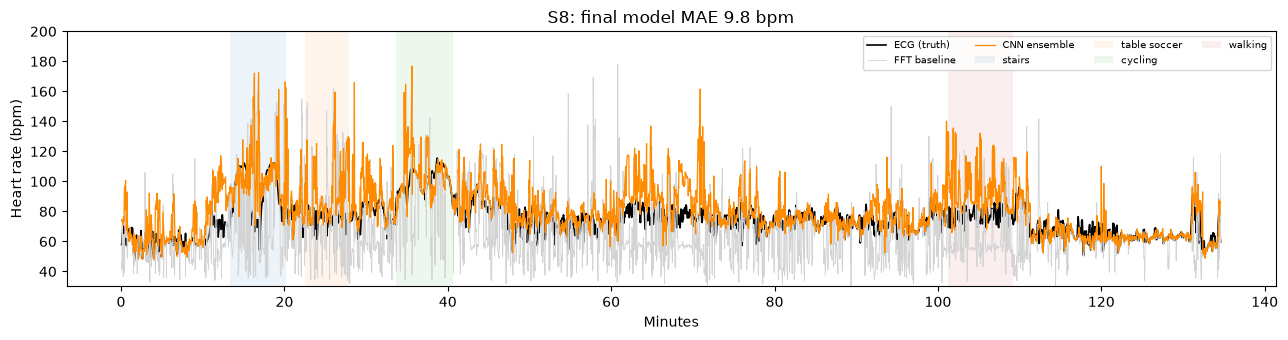

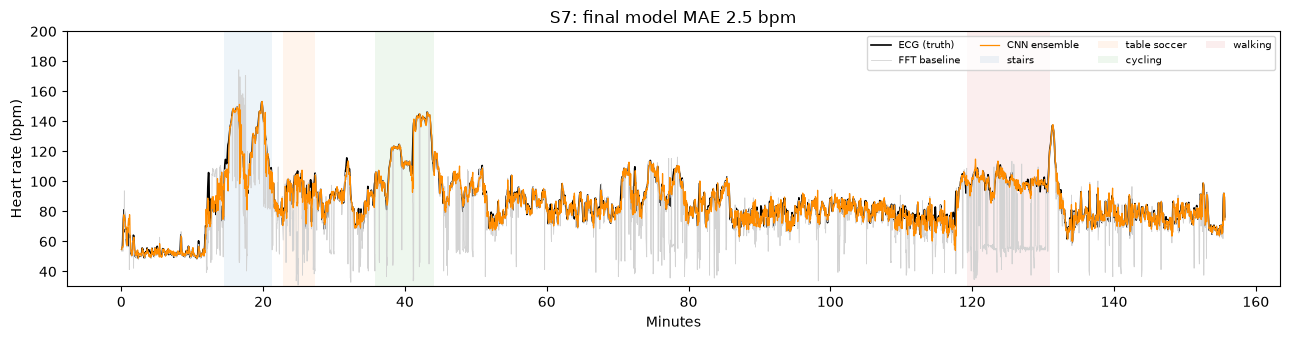

In [9]:
def tracking_plot(subject):
    rows = subjects == subject
    minutes = (np.arange(rows.sum()) * 2 + 4) / 60
    fig, ax = plt.subplots(figsize=(13, 3.5))
    ax.plot(minutes, truth[rows], color="black", linewidth=1.2, label="ECG (truth)")
    ax.plot(minutes, methods["FFT baseline"][rows], color="lightgray", linewidth=0.6, label="FFT baseline")
    ax.plot(minutes, final[rows], color="darkorange", linewidth=0.9, label="CNN ensemble")
    acts = activity[rows]
    for a in ["stairs", "table soccer", "cycling", "walking"]:
        on = acts == a
        if on.any():
            ax.fill_between(minutes, 30, 200, where=on, alpha=0.08, label=a)
    ax.set_ylim(30, 200)
    ax.set_xlabel("Minutes")
    ax.set_ylabel("Heart rate (bpm)")
    mae = np.abs(final[rows] - truth[rows]).mean()
    ax.set_title(f"S{subject}: final model MAE {mae:.1f} bpm")
    ax.legend(loc="upper right", fontsize=7, ncol=4)
    plt.tight_layout()
    plt.show()

worst = people["MAE: CNN ensemble (3)"].idxmax()
best = people["MAE: CNN ensemble (3)"].idxmin()
print("Worst person:", worst, "  Best person:", best)
tracking_plot(int(worst[1:]))
tracking_plot(int(best[1:]))

## 7. Are the improvements real across people? (paired statistics)

Each person is one data point (15 points), because windows from the same person are not independent. The **Wilcoxon signed-rank test** asks: across people, is method A's error consistently lower than method B's?

In [10]:
comparisons = []
for a, b in [("CNN ensemble (3)", "FFT baseline"), ("CNN ensemble (3)", "Gradient boosting"),
             ("CNN ensemble (3)", "CNN (1 network)")]:
    mae_a, mae_b = people[f"MAE: {a}"], people[f"MAE: {b}"]
    comparisons.append({
        "comparison": f"{a} vs {b}",
        "people improved": f"{int((mae_a < mae_b).sum())} of {len(mae_a)}",
        "median improvement (bpm)": round(float((mae_b - mae_a).median()), 2),
        "Wilcoxon p-value": round(float(stats.wilcoxon(mae_a, mae_b).pvalue), 4),
    })
pd.DataFrame(comparisons)

,comparison,people improved,median improvement (bpm),Wilcoxon p-value
0,CNN ensemble (3) vs FFT baseline,15 of 15,9.60,0.0001
1,CNN ensemble (3) vs Gradient boosting,13 of 15,0.98,0.0026
2,CNN ensemble (3) vs CNN (1 network),15 of 15,0.31,0.0001


## 8. Save the summary

In [11]:
summary = {
    "agreement": table.round(3).to_dict(orient="index"),
    "mae_by_activity": by_activity.to_dict(orient="index"),
    "big_error_anatomy_percent": anatomy.to_dict(),
    "per_person": people.round(2).to_dict(orient="index"),
    "paired_tests": comparisons,
}
with open(PROJECT_DIR / "results" / "step10_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)
print("Saved results/step10_summary.json")

Saved results/step10_summary.json
